# 03 · Tabel Fitur v1 (train + test)

Notebook ini mengubah semua temuan EDA menjadi **satu tabel fitur final**, dihitung dengan fungsi yang **sama persis** untuk train dan test (`features.build_features`), lalu memeriksa bahwa tabel itu aman dipakai sebelum masuk ke modeling.

**Output** (dibaca oleh notebook 04 dan eksperimen berikutnya, jadi fitur tidak perlu dihitung ulang setiap kali):

| File | Isi |
|---|---|
| `data/features/train_v1.parquet` | 1 baris per aplikasi train: ID, `target`, semua fitur |
| `data/features/test_v1.parquet` | 1 baris per aplikasi test: ID, semua fitur |
| `data/features/features_v1.json` | daftar fitur, fitur kategorikal, sumber tiap fitur, versi data e-commerce |

**Pemeriksaan** sebelum disimpan:

| # | Pemeriksaan | Kenapa penting |
|---|---|---|
| C1 | Jumlah baris & ID unik sama dengan tabel aplikasi; ID test = `sample_submission` | join yang salah bisa menggandakan / menghilangkan baris |
| C2 | Kolom & tipe data train = test | model yang dilatih di train harus menerima test tanpa penyesuaian |
| C3 | Tidak ada `target`, ID, atau tanggal mentah di daftar fitur; tidak ada ±inf / NaN | kebocoran & error model |
| C4 | Fitur konstan / hampir konstan | tidak membawa informasi |
| C5 | Selisih tingkat null train vs test | beda cakupan = beda cara pembuatan fitur |
| C6 | Drift distribusi train vs test (KS per fitur) + *adversarial validation* | apakah validasi silang di train mewakili test |

> **Satu aturan penting:** kalau Anda memakai file e-commerce penuh, train **dan** test harus dibangun dari file yang sama. Fitur jumlah/nilai belanja bergantung pada versi file.

In [1]:
import gc
import json
import time
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
import eda_utils as E
import features as F
import modeling as M

E.setup_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

manifest = json.loads((E.PQ_DIR / "_manifest.json").read_text())
print("Sumber e-commerce :", manifest["ecommerce_source"], "| sampling:", manifest["ecommerce_is_sampled"])
print("Polars            :", pl.__version__)

Sumber e-commerce : ecommerce_transactions.csv | sampling: False
Polars            : 2.0.0


## 1. Bangun fitur

Langkah di dalam `build_features(app, T)`:

1. Setiap aplikasi membawa **cutoff = `decision_datetime`-nya sendiri**. Semua fitur riwayat (pengajuan lama, cicilan, biro, rekening, e-commerce) dihitung hanya dari kejadian **sebelum** cutoff tersebut.
2. Fitur tiap sumber dibuat oleh fungsi masing-masing (`prev_app_features`, `loan_features`, `repayment_features`, `bureau_features`, `account_features`, `ecommerce_features`), lalu di-*join* ke tabel aplikasi per `customer_id`. Setiap nasabah hanya punya satu aplikasi, jadi join ini 1-ke-1.
3. Fitur gabungan lintas sumber (DTI, total DTI, buffer saldo, dll.) dan label `segment` (A/B/C) ditambahkan di akhir.
4. Tipe dirapikan: boolean → 0/1, pembagian dengan nol (±inf / NaN) → null.

**Hemat memori.** File e-commerce penuh (4,4 juta baris) adalah bagian terberat. Fitur e-commerce dihitung per kelompok **10.000 nasabah**: hanya transaksi milik kelompok itu yang dibaca dari parquet. Hasilnya identik dengan menghitung sekaligus, tetapi tambahan RAM-nya turun dari ~700 MB menjadi ~90 MB (diukur di data sampling, dan kira-kira dua kali lipat untuk file penuh). Setelah tabel fitur jadi, tabel mentah dihapus dari memori. Bila RAM masih kurang, perkecil `ECOM_BATCH` di bawah, misalnya menjadi 5_000.

**Satu-satunya konstanta global** adalah median harga per kategori untuk fitur *price premium*. Konstanta ini dihitung **hanya dari transaksi sebelum keputusan paling awal** (1 Januari 2025), sehingga "tersedia sebelum" setiap `decision_datetime`, dan tidak memakai target. Di data sampling, KS `ec_price_premium_mean` tidak berubah (0,3411 dengan median semua transaksi vs 0,3410 dengan median sebelum 2025), jadi kepatuhan aturan ini tidak mengurangi sinyal.

In [2]:
ECOM_BATCH = 10_000          # nasabah per kelompok untuk fitur e-commerce; perkecil bila RAM terbatas

t0 = time.time()
T = F.load_tables(E.load, E.lazy)
app_tr = E.load("train_applications")
app_te = E.load("test_applications")
train = F.build_features(app_tr, T, ecom_batch_size=ECOM_BATCH)
test = F.build_features(app_te, T, ecom_batch_size=ECOM_BATCH)
FEATURES = F.feature_columns(train)
CATS = [c for c in F.APP_CATEGORICAL if c in FEATURES]
first_decision, cat_medians = T["first_decision"], T["ecom_cat_medians"]
del T                        # tabel mentah tidak diperlukan lagi → bebaskan RAM
gc.collect()
print(f"train {train.shape} | test {test.shape} | {len(FEATURES)} fitur ({len(CATS)} kategorikal) | {time.time() - t0:.0f} detik")
print("Median kategori dihitung dari transaksi sebelum:", first_decision)
cat_medians.sort("cat_median_unit")

train (70000, 194) | test (30000, 193) | 191 fitur (6 kategorikal) | 8 detik
Median kategori dihitung dari transaksi sebelum: 2025-01-01 08:00:00


product_category,cat_median_unit
str,f64
"""groceries""",56000.0
"""personal_care""",71000.0
"""education""",96000.0
"""health""",112000.0
"""fashion""",163000.0
"""home""",285000.0
"""electronics""",1.125e6


Jumlah fitur per sumber:

In [3]:
groups = pl.DataFrame({"feature": FEATURES, "sumber": [F.feature_group(c) for c in FEATURES]})
(groups.group_by("sumber").agg(n_fitur=pl.len(), contoh=pl.col("feature").head(4).str.join(", "))
       .sort(pl.col("sumber").replace_strict({g: i for i, g in enumerate(F.FEATURE_GROUPS)}, return_dtype=pl.Int8)))

sumber,n_fitur,contoh
str,u32,str
"""aplikasi_profil""",14,"""loan_amount, annual_interest_rate, proposed_monthly_installm…"
"""internal""",52,"""pa_n, pa_n_approved, pa_n_rejected, pa_n_cancelled"""
"""biro""",33,"""bu_n_reports, bu_n_unscored, bu_score_mean, bu_score_min"""
"""rekening""",42,"""ac_n_months, ac_avg_bal_3m, ac_min_bal_3m, ac_income_3m"""
"""ecommerce""",50,"""ec_n_orders_all, ec_spend_all, ec_days_since_last_order, ec_…"


## 2. Pemeriksaan konsistensi (C1–C5)

Setiap pemeriksaan menghasilkan PASS/FAIL. Semua harus PASS sebelum tabel disimpan.

In [4]:
checks = []
def check(kode, nama, ok, detail=""):
    checks.append(dict(kode=kode, pemeriksaan=nama, hasil="PASS" if ok else "FAIL", detail=str(detail)))

ss = E.load("sample_submission")
# C1 — baris & ID
check("C1", "baris train = train_applications", train.height == app_tr.height, f"{train.height:,}")
check("C1", "baris test = test_applications", test.height == app_te.height, f"{test.height:,}")
check("C1", "application_id unik (train & test)",
      train["application_id"].n_unique() == train.height and test["application_id"].n_unique() == test.height)
check("C1", "ID test = ID sample_submission", set(test["application_id"]) == set(ss["application_id"]), f"{ss.height:,} ID")
check("C1", "tidak ada ID / nasabah yang sama di train & test",
      not (set(train["application_id"]) & set(test["application_id"])) and not (set(train["customer_id"]) & set(test["customer_id"])))
check("C1", "target tidak berubah oleh join",
      train.select("application_id", "target").sort("application_id").equals(app_tr.select("application_id", "target").sort("application_id")),
      f"default rate {train['target'].mean():.4f}")
# C2 — kolom & tipe
check("C2", "kolom test = kolom train tanpa target", [c for c in train.columns if c != "target"] == test.columns)
dtype_diff = [c for c in FEATURES if train.schema[c] != test.schema[c]]
check("C2", "tipe data fitur train = test", not dtype_diff, dtype_diff or "")
non_numeric = [c for c in FEATURES if not train.schema[c].is_numeric()]
check("C2", "fitur non-numerik hanya kategorikal yang terdaftar", sorted(non_numeric) == sorted(CATS), non_numeric)
# C3 — kebocoran & nilai tak hingga
forbidden = {"target", "application_id", "customer_id", "decision_datetime"}
check("C3", "tidak ada target / ID / tanggal mentah di fitur", not (forbidden & set(FEATURES)))
floats = [c for c in FEATURES if train.schema[c] in (pl.Float32, pl.Float64)]
bad_vals = {c: int(d[c].is_infinite().sum() + d[c].is_nan().sum()) for d in (train, test) for c in floats
            if d[c].is_infinite().sum() + d[c].is_nan().sum() > 0}
check("C3", "tidak ada ±inf / NaN", not bad_vals, bad_vals or "")
# C4 — fitur (hampir) konstan
top_share = {c: train[c].value_counts(sort=True)["count"][0] / train.height for c in FEATURES}
constant = [c for c in FEATURES if train[c].n_unique() <= 1]
near_constant = [c for c, s in top_share.items() if s > 0.995 and c not in constant]
check("C4", "tidak ada fitur konstan", not constant, constant or "")
# C5 — tingkat null
null_cmp = (pl.DataFrame({"feature": FEATURES,
                          "null_train": [train[c].null_count() / train.height for c in FEATURES],
                          "null_test": [test[c].null_count() / test.height for c in FEATURES]})
              .with_columns(selisih=(pl.col("null_test") - pl.col("null_train")).abs()))
check("C5", "selisih null train vs test < 2 poin persen", null_cmp["selisih"].max() < 0.02,
      f"maks {null_cmp['selisih'].max():.4f} ({null_cmp.sort('selisih')['feature'][-1]})")

pl.DataFrame(checks)

kode,pemeriksaan,hasil,detail
str,str,str,str
"""C1""","""baris train = train_applications""","""PASS""","""70,000"""
"""C1""","""baris test = test_applications""","""PASS""","""30,000"""
"""C1""","""application_id unik (train & test)""","""PASS""",""""""
"""C1""","""ID test = ID sample_submission""","""PASS""","""30,000 ID"""
"""C1""","""tidak ada ID / nasabah yang sama di train & test""","""PASS""",""""""
"""C1""","""target tidak berubah oleh join""","""PASS""","""default rate 0.1358"""
"""C2""","""kolom test = kolom train tanpa target""","""PASS""",""""""
"""C2""","""tipe data fitur train = test""","""PASS""",""""""
"""C2""","""fitur non-numerik hanya kategorikal yang terdaftar""","""PASS""","""['loan_purpose', 'region', 'employment_type', 'housing_statu…"


In [5]:
print(f"Fitur hampir konstan (nilai terbanyak > 99,5% baris): {len(near_constant)}")
print("5 fitur dengan nilai paling dominan (null dihitung sebagai satu nilai):")
pl.DataFrame({"feature": list(top_share), "share_nilai_terbanyak": list(top_share.values())}).sort(
    "share_nilai_terbanyak", descending=True).head(5).with_columns(pl.col("share_nilai_terbanyak").round(4))

Fitur hampir konstan (nilai terbanyak > 99,5% baris): 0
5 fitur dengan nilai paling dominan (null dihitung sebagai satu nilai):


feature,share_nilai_terbanyak
str,f64
"""bu_n_unscored""",0.8626
"""ec_pay_share_credit_card""",0.8143
"""pa_days_since_last_reject""",0.8021
"""bu_n_reports""",0.6733
"""segment""",0.6616


**Cara membaca:** semua pemeriksaan C1–C5 harus PASS. Tidak ada fitur yang mendekati konstan. Fitur paling dominan, `bu_n_unscored` (86% bernilai 0), adalah fitur kejadian yang jarang terjadi: jarang muncul, tetapi bermakna saat muncul. Fitur seperti ini sengaja **tidak** dibuang karena GBDT bisa memakainya tanpa merugikan fitur lain. Ambang buang hanya berlaku untuk fitur yang benar-benar konstan.

Tingkat null per sumber (train vs test) memperlihatkan cakupan tiap sumber:

In [6]:
(null_cmp.join(groups, on="feature")
         .group_by("sumber").agg(pl.col("null_train").mean().round(3).alias("rata2_null_train"),
                                 pl.col("null_test").mean().round(3).alias("rata2_null_test"),
                                 pl.col("selisih").max().round(4).alias("selisih_maks"))
         .sort(pl.col("sumber").replace_strict({g: i for i, g in enumerate(F.FEATURE_GROUPS)}, return_dtype=pl.Int8)))

sumber,rata2_null_train,rata2_null_test,selisih_maks
str,f64,f64,f64
"""aplikasi_profil""",0.0,0.0,0.0
"""internal""",0.331,0.331,0.0028
"""biro""",0.106,0.106,0.0022
"""rekening""",0.3,0.3,0.0
"""ecommerce""",0.018,0.018,0.0012


## 3. Drift train vs test (C6)

Pertanyaannya: **apakah test berasal dari populasi yang sama dengan train?** Jika ya, skor validasi silang (CV) di train adalah perkiraan yang jujur untuk leaderboard.

Dua cara memeriksa:

1. **KS per fitur (train vs test).** KS di sini mengukur beda distribusi fitur antara dua tabel, bukan daya pembeda target. Dengan 70.000 vs 30.000 baris, nilai kritis 5% adalah $1{,}36\sqrt{(n_1+n_2)/(n_1 n_2)} \approx 0{,}0094$.
2. ***Adversarial validation*.** Latih model untuk menebak "baris ini dari train atau test?". AUC ≈ 0,5 berarti model tidak bisa membedakan keduanya, jadi tidak ada drift yang berarti. AUC jauh di atas 0,5 menunjukkan fitur mana yang berbeda.

**Pembanding yang adil (sama seperti *noise floor* di EDA):** banyak fitur saling berkorelasi, misalnya saldo 3 bulan, 6 bulan, dan seluruh periode. Kalau satu fitur kebetulan melewati batas, "saudaranya" ikut melewatinya, sehingga angka "5% fitur" terlalu optimistis. Karena itu kedua cek dibandingkan dengan **pembagian acak buatan**: gabungkan train + test, bagi ulang secara acak menjadi 70.000/30.000 baris, lalu hitung statistik yang sama. Hasil asli yang masih berada dalam rentang pembagian acak berarti tidak ada drift.

Konteks dari audit: train dan test mencakup periode yang sama (Jan–Des 2025), tanpa nasabah yang sama. Pembagiannya tampak **acak**, sehingga kedua cek di atas diperkirakan bersih.

In [7]:
num_feats = [c for c in FEATURES if c not in CATS]
crit = 1.36 * np.sqrt((train.height + test.height) / (train.height * test.height))
drift = []
for c in num_feats:
    a, b = train[c].drop_nulls().to_numpy(), test[c].drop_nulls().to_numpy()
    if len(a) > 50 and len(b) > 50:
        drift.append(dict(feature=c, sumber=F.feature_group(c), ks_train_vs_test=float(ks_2samp(a, b).statistic)))
drift = pl.DataFrame(drift).sort("ks_train_vs_test", descending=True)
n_over = int((drift["ks_train_vs_test"] > crit).sum())

# pembanding: 20 pembagian acak buatan 70.000 / 30.000 dari tabel gabungan
pool = {c: pl.concat([train[c], test[c]]).to_numpy() for c in drift["feature"]}
rng = np.random.default_rng(0)
perm_over, perm_max = [], []
for r in range(20):
    fake_test = np.zeros(train.height + test.height, bool)
    fake_test[rng.choice(len(fake_test), test.height, replace=False)] = True
    ks_r = []
    for c, x in pool.items():
        ok = ~np.isnan(x)
        ks_r.append(ks_2samp(x[ok & ~fake_test], x[ok & fake_test]).statistic)
    perm_over.append(int((np.array(ks_r) > crit).sum())); perm_max.append(max(ks_r))
perm_over_p95 = float(np.percentile(perm_over, 95))
print(f"Nilai kritis 5%: {crit:.4f}")
print(f"Fitur di atas kritis  — asli: {n_over} dari {drift.height} | pembagian acak: median {np.median(perm_over):.0f}, "
      f"rentang {min(perm_over)}–{max(perm_over)}, persentil 95 = {perm_over_p95:.0f}")
print(f"KS maksimum           — asli: {drift['ks_train_vs_test'].max():.4f} | pembagian acak: "
      f"{min(perm_max):.4f}–{max(perm_max):.4f}")
del pool; gc.collect()
drift.head(10)

Nilai kritis 5%: 0.0094
Fitur di atas kritis  — asli: 16 dari 185 | pembagian acak: median 12, rentang 4–23, persentil 95 = 21
KS maksimum           — asli: 0.0138 | pembagian acak: 0.0118–0.0198


feature,sumber,ks_train_vs_test
str,str,f64
"""bu_util_mean""","""biro""",0.013776
"""ac_out_in_ratio_3m""","""rekening""",0.012673
"""bu_all_util_mean""","""biro""",0.012502
"""ac_last_closing""","""rekening""",0.011837
"""bu_all_inq_mean""","""biro""",0.011824
"""ac_avg_bal_all""","""rekening""",0.010986
"""ac_avg_bal_6m""","""rekening""",0.010667
"""ac_min_bal_3m""","""rekening""",0.010537
"""bu_inq_mean""","""biro""",0.010405


In [8]:
both = pl.concat([train.select(FEATURES).with_columns(is_test=pl.lit(0)),
                  test.select(FEATURES).with_columns(is_test=pl.lit(1))])
adv_oof, adv_ks, adv_auc, adv_imp = E.cv_lgb(both, FEATURES, y="is_test", cat_features=CATS, seed=42)
# pembanding: label train/test diacak → AUC yang didapat murni dari kebetulan + early stopping di fold validasi
fake = np.zeros(both.height, int); fake[rng.choice(both.height, test.height, replace=False)] = 1
_, _, adv_auc_null, _ = E.cv_lgb(both.with_columns(is_test=pl.Series(fake)), FEATURES, y="is_test", cat_features=CATS, seed=42)
check("C6", "adversarial AUC ≤ AUC label acak + 0,01", adv_auc <= adv_auc_null + 0.01,
      f"AUC {adv_auc:.4f} vs acak {adv_auc_null:.4f}")
check("C6", "jumlah fitur KS > kritis ≤ persentil 95 pembagian acak", n_over <= perm_over_p95,
      f"{n_over} vs p95 {perm_over_p95:.0f}")
print(f"Adversarial validation: AUC {adv_auc:.4f} | dengan label acak: {adv_auc_null:.4f}")
print("Fitur yang paling dipakai model adversarial (bila AUC ≈ acak, daftar ini hanya noise):")
adv_imp.head(8)

Adversarial validation: AUC 0.5040 | dengan label acak: 0.5034
Fitur yang paling dipakai model adversarial (bila AUC ≈ acak, daftar ini hanya noise):


feature,gain_pct
str,f64
"""bu_util_mean""",2.525666
"""bu_all_util_mean""",2.24835
"""ec_spend_surge_90d""",1.996541
"""ec_cat_share_personal_care""",1.994421
"""bu_outstanding_to_income""",1.961698
"""bu_rev_out_max""",1.953165
"""bu_report_age_min""",1.851636
"""ac_out_in_ratio_3m""",1.839345


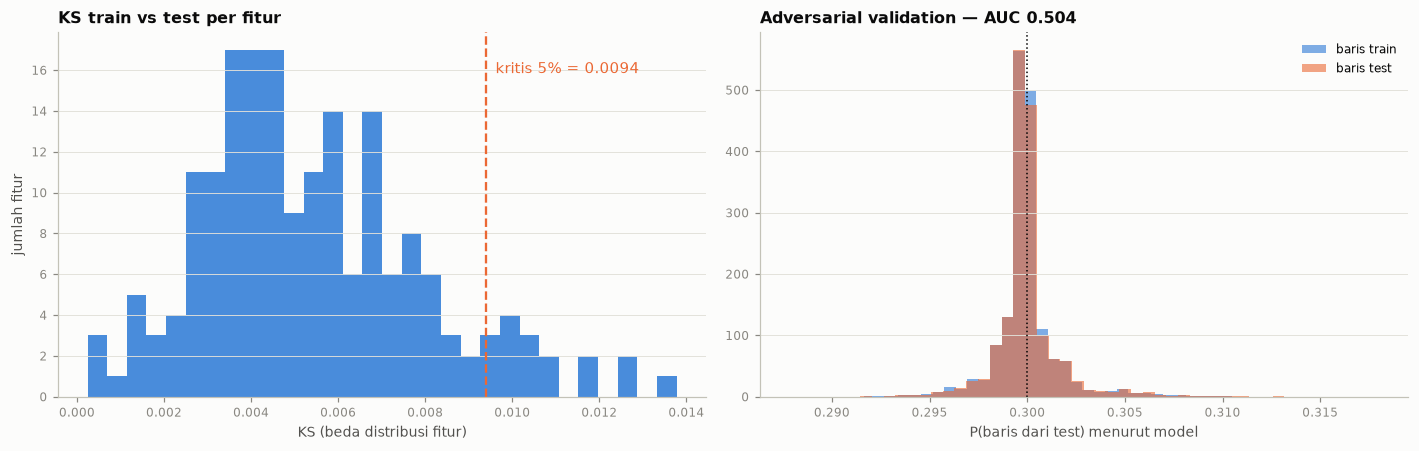

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.hist(drift["ks_train_vs_test"], bins=30, color=E.C_RATE, alpha=0.85)
ax.axvline(crit, color=E.SERIES[1], ls="--", lw=1.5)
ax.text(crit, ax.get_ylim()[1] * 0.92, f"  kritis 5% = {crit:.4f}", color=E.SERIES[1], va="top")
ax.set_title("KS train vs test per fitur", loc="left")
ax.set_xlabel("KS (beda distribusi fitur)"); ax.set_ylabel("jumlah fitur")
ax = axes[1]
ax.hist(adv_oof[both["is_test"].to_numpy() == 0], bins=50, alpha=0.6, density=True, label="baris train", color=E.SERIES[0])
ax.hist(adv_oof[both["is_test"].to_numpy() == 1], bins=50, alpha=0.6, density=True, label="baris test", color=E.SERIES[1])
ax.axvline(test.height / both.height, color="black", lw=1, ls=":")
ax.set_title(f"Adversarial validation — AUC {adv_auc:.3f}", loc="left")
ax.set_xlabel("P(baris dari test) menurut model"); ax.legend()
plt.tight_layout(); plt.show()

**Cara membaca grafik:**

- **Kiri:** sebagian besar fitur berada di bawah garis kritis. Jumlah yang melewatinya, dan seberapa jauh, masih dalam rentang yang muncul ketika data dibagi secara acak murni (lihat output di atas). Fitur yang paling "berbeda" (utilisasi biro, saldo rekening) hanya berbeda ~0,014, dan pembagian acak menghasilkan maksimum yang serupa.
- **Kanan:** kalau ada drift, kurva oranye (test) akan bergeser ke kanan dari kurva biru (train). Kurva yang bertumpuk berarti model tidak menemukan pembeda. AUC adversarial juga sama dengan AUC dari label yang diacak.

Kesimpulan: test berasal dari populasi yang sama dengan train. Akibatnya:

1. **StratifiedKFold acak** adalah skema validasi yang tepat. Validasi berbasis waktu tidak diperlukan karena test tidak berada "di masa depan" relatif terhadap train.
2. KS CV adalah perkiraan yang jujur untuk leaderboard, dengan noise sampling ±0,012 di public LB (EDA 6, Q7).

## 4. Ringkasan pemeriksaan & simpan

In [10]:
summary = pl.DataFrame(checks)
n_fail = (summary["hasil"] == "FAIL").sum()
print(f"{summary.height} pemeriksaan | PASS {summary.height - n_fail} | FAIL {n_fail}")
summary

15 pemeriksaan | PASS 15 | FAIL 0


kode,pemeriksaan,hasil,detail
str,str,str,str
"""C1""","""baris train = train_applications""","""PASS""","""70,000"""
"""C1""","""baris test = test_applications""","""PASS""","""30,000"""
"""C1""","""application_id unik (train & test)""","""PASS""",""""""
"""C1""","""ID test = ID sample_submission""","""PASS""","""30,000 ID"""
"""C1""","""tidak ada ID / nasabah yang sama di train & test""","""PASS""",""""""
"""C1""","""target tidak berubah oleh join""","""PASS""","""default rate 0.1358"""
"""C2""","""kolom test = kolom train tanpa target""","""PASS""",""""""
"""C2""","""tipe data fitur train = test""","""PASS""",""""""
"""C2""","""fitur non-numerik hanya kategorikal yang terdaftar""","""PASS""","""['loan_purpose', 'region', 'employment_type', 'housing_statu…"


In [11]:
assert n_fail == 0, "Ada pemeriksaan FAIL — perbaiki sebelum menyimpan"
M.FEAT_DIR.mkdir(parents=True, exist_ok=True)
train.write_parquet(M.FEAT_DIR / "train_v1.parquet")
test.write_parquet(M.FEAT_DIR / "test_v1.parquet")
meta = dict(
    version="v1",
    created=time.strftime("%Y-%m-%d %H:%M:%S"),
    polars_version=pl.__version__,
    ecommerce_source=manifest["ecommerce_source"],
    ecommerce_is_sampled=manifest["ecommerce_is_sampled"],
    ecom_median_before=str(first_decision),
    n_train=train.height, n_test=test.height,
    features=FEATURES,
    categorical=CATS,
    groups={g: [c for c in FEATURES if F.feature_group(c) == g] for g in F.FEATURE_GROUPS},
)
(M.FEAT_DIR / "features_v1.json").write_text(json.dumps(meta, indent=2))
for p in sorted(M.FEAT_DIR.iterdir()):
    print(f"{p.name:24s} {p.stat().st_size / 1e6:6.1f} MB")

features_v1.json            0.0 MB
test_v1.parquet            14.9 MB
train_v1.parquet           34.2 MB
